<a href="https://colab.research.google.com/github/Ethan-Tse/Problem-Set-5-Econ_3916_PS5.ipynb/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS5: Right 93% of the Time

## Setup

In [10]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
RANDOM_STATE = 42
pd.set_option('display.precision', 3)
warnings.filterwarnings('ignore', category=FutureWarning)    # scikit-learn is retiring the `penalty` argument; it still works

## Phase 1: Build the Baseline Nobody Built

### Step 1.1: The data

In [11]:
# Step 1.1: simulate the applications, then split BEFORE looking at anything.
# Units: income and loan amount in dollars, credit history in years, debt-to-income as a ratio.
from sklearn.model_selection import train_test_split
from sklearn import metrics

N_APPS = 10_000                      # at least 5,000 applications
TARGET_PREVALENCE = 0.07             # roughly 7% default

income  = np.exp(rng.normal(10.9, 0.5, N_APPS))
dti     = np.clip(rng.beta(2.2, 5.5, N_APPS) * 1.1, 0.02, 0.85)
history = np.clip(rng.gamma(4.0, 3.0, N_APPS), 0.5, 40)
delinq  = rng.poisson(0.45, N_APPS)
loan    = np.exp(rng.normal(9.4, 0.6, N_APPS) + 0.35 * (np.log(income) - 10.9))
loan_to_income = loan / income

apps = pd.DataFrame({"income": income, "debt_to_income": dti, "credit_history_years": history,
                     "prior_delinquencies": delinq, "loan_amount": loan})
# six features with no true relationship to default
apps["application_weekday"] = rng.integers(0, 7, N_APPS)
apps["email_name_length"] = rng.integers(4, 26, N_APPS)
apps["marketing_channel"] = rng.integers(0, 8, N_APPS)
apps["browser_code"] = rng.integers(0, 5, N_APPS)
apps["form_seconds"] = np.exp(rng.normal(5.0, 0.6, N_APPS))
apps["postcode_digit_sum"] = rng.integers(5, 40, N_APPS)
REAL = ["income", "debt_to_income", "credit_history_years", "prior_delinquencies", "loan_amount"]
IRRELEVANT = [c for c in apps.columns if c not in REAL]

# The truth: log-odds of default, with a threshold effect and an interaction the straight-line model cannot see
z = (-0.95 * (np.log(income) - 10.9) / 0.5 + 3.2 * dti + 7.0 * np.clip(dti - 0.42, 0, None)
     + 0.75 * delinq + 0.9 * delinq * (dti > 0.3) - 0.07 * history
     + 1.1 * (loan_to_income - loan_to_income.mean()) / loan_to_income.std())
intercept = brentq(lambda c: np.mean(1 / (1 + np.exp(-(z + c)))) - TARGET_PREVALENCE, -15, 5)   # set so the default rate is about 7%
p_true = 1 / (1 + np.exp(-(z + intercept)))
default = pd.Series((rng.random(N_APPS) < p_true).astype(int), name="default")
p_true = pd.Series(p_true, name="p_true")

# the split, straight away: every number from here on comes from the test set
X_train, X_test, y_train, y_test, ptrue_train, ptrue_test = train_test_split(
    apps, default, p_true, test_size=0.3, stratify=default, random_state=RANDOM_STATE)

print(f"applications: {N_APPS:,}; train {len(X_train):,} (default rate {y_train.mean():.1%}), "
      f"test {len(X_test):,} (default rate {y_test.mean():.1%}, {int(y_test.sum())} defaults)")
print(f"features: {len(REAL)} real {REAL}")
print(f"          {len(IRRELEVANT)} with no relationship to default {IRRELEVANT}")
print(f"the best any model could do in this world: ROC AUC {metrics.roc_auc_score(y_test, ptrue_test):.3f} on the test rows (from the true probabilities)")
display(X_train.describe().loc[["mean", "50%", "std", "min", "max"], REAL].round(2))

applications: 10,000; train 7,000 (default rate 7.0%), test 3,000 (default rate 7.0%, 209 defaults)
features: 5 real ['income', 'debt_to_income', 'credit_history_years', 'prior_delinquencies', 'loan_amount']
          6 with no relationship to default ['application_weekday', 'email_name_length', 'marketing_channel', 'browser_code', 'form_seconds', 'postcode_digit_sum']
the best any model could do in this world: ROC AUC 0.944 on the test rows (from the true probabilities)


,income,debt_to_income,credit_history_years,prior_delinquencies,loan_amount
mean,61494.56,0.31,12.01,0.44,14569.57
50%,54199.47,0.29,11.02,0.00,11757.62
std,32672.79,0.17,6.01,0.67,10245.01
min,6035.67,0.02,0.87,0.00,1371.10
max,304681.79,0.85,40.00,4.00,168412.49


*The data-generating process, recorded.* 10,000 applications, 11 features. Units: income and loan amount in dollars, credit history in years, debt-to-income as a ratio.

- **The split.** A stratified 70/30 split, made immediately after simulating and before any model or summary: 7,000 training and 3,000 test applications. The test set has a default rate of 7.0% (209 defaults). Every number from here on comes from the test set. In this simulated world the best any model could do, using the true probabilities, has a test ROC AUC of 0.944.

### Step 1.2: The null model

In [12]:
# Step 1.2: the null model, "no default" for everyone
from sklearn.dummy import DummyClassifier
from sklearn import metrics

null = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
null_pred = null.predict(X_test)
null_acc = metrics.accuracy_score(y_test, null_pred)
print(f"null model: predicts '{null_pred[0]}' (no default) for all {len(null_pred):,} test applications")
print(f"accuracy {null_acc:.4f}  (= 1 - the test default rate of {y_test.mean():.4f})")
tn, fp, fn, tp = metrics.confusion_matrix(y_test, null_pred, labels=[0, 1]).ravel()
print(f"it approves all {tn:,} good applicants and all {fn} defaulters: recall {tp / (tp + fn):.3f}, no applicant ever flagged")

null model: predicts '0' (no default) for all 3,000 test applications
accuracy 0.9303  (= 1 - the test default rate of 0.0697)
it approves all 2,791 good applicants and all 209 defaulters: recall 0.000, no applicant ever flagged


**The floor.** The null model predicts "no default" for all 3,000 test applications and scores an accuracy of 0.9303, which is 1 minus the 0.0697 default rate. It approves all 2,791 good applicants and all 209 defaulters, so it flags no one and its recall is zero.

The vendor's 93% is what a model that has learned nothing scores. It is also what a good model might score, and the one-page summary cannot tell the two apart. The sentence for the meeting: **"Approving everybody is 93% accurate, so 93% accuracy proves nothing; show me what the model does on the 7% who default."** A model has to beat 0.9303 by more than chance to have demonstrated anything, and Step 3.1 tests that.

## Phase 2: Fit and Regularise

### Step 2.1: Logistic regression, then penalised

chosen C: LASSO 0.8532 (CV minimum) and 0.0304 (one-standard-error rule), Ridge 3.5622  (smaller C = stronger penalty)

coefficients on standardised features:
                      unpenalised  Ridge  LASSO (CV min)  LASSO (1-SE)
income                     -2.774 -2.745          -2.737        -1.984
debt_to_income              1.254  1.248           1.243         0.999
credit_history_years       -0.604 -0.600          -0.594        -0.384
prior_delinquencies         0.849  0.845           0.842         0.680
loan_amount                 1.070  1.063           1.057         0.791
application_weekday        -0.019 -0.018          -0.015         0.000
email_name_length           0.037  0.039           0.034         0.000
marketing_channel          -0.066 -0.065          -0.062         0.000
browser_code                0.061  0.061           0.056         0.000
form_seconds                0.090  0.090           0.086         0.000
postcode_digit_sum         -0.057 -0.058          -0.053    

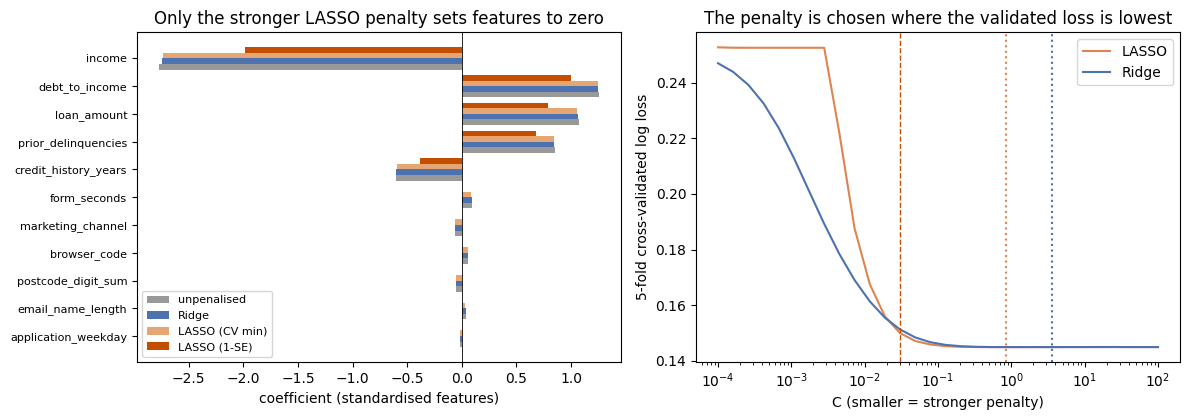

In [13]:
# Step 2.1: logistic regression, then LASSO and Ridge with the penalty chosen by cross-validation on the training rows
import warnings
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn import metrics

Cs = np.logspace(-4, 2, 30)           # a range of penalty strengths (C is the inverse of the penalty)
plain = make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5000))              # essentially unpenalised
lasso = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=Cs, cv=5, penalty="l1", solver="saga",
                      scoring="neg_log_loss", max_iter=10_000, random_state=RANDOM_STATE))
ridge = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=Cs, cv=5, penalty="l2",
                      scoring="neg_log_loss", max_iter=5000, random_state=RANDOM_STATE))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for m in (plain, lasso, ridge):
        m.fit(X_train, y_train)

# LASSO at the CV-minimum penalty is tuned for prediction, not for selection. The one-standard-error rule picks the strongest
# penalty whose validated loss is within one standard error of the best, and is the usual way to ask LASSO for a sparser model
fold_loss = -lasso[-1].scores_[1]                                   # log loss for each fold and each C
mean_loss, se_loss = fold_loss.mean(0), fold_loss.std(0, ddof=1) / np.sqrt(fold_loss.shape[0])
C_1se = lasso[-1].Cs_[mean_loss <= mean_loss.min() + se_loss[mean_loss.argmin()]].min()
lasso_1se = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="saga", C=C_1se, max_iter=10_000, random_state=RANDOM_STATE))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lasso_1se.fit(X_train, y_train)

coefs = pd.DataFrame({"unpenalised": plain[-1].coef_[0], "Ridge": ridge[-1].coef_[0],
                      "LASSO (CV min)": lasso[-1].coef_[0], "LASSO (1-SE)": lasso_1se[-1].coef_[0]}, index=X_train.columns)
print(f"chosen C: LASSO {lasso[-1].C_[0]:.4f} (CV minimum) and {C_1se:.4f} (one-standard-error rule), Ridge {ridge[-1].C_[0]:.4f}  (smaller C = stronger penalty)")
print("\ncoefficients on standardised features:")
print(coefs.round(3).to_string())

for label in ("LASSO (CV min)", "LASSO (1-SE)"):
    zeroed = [c for c in coefs.index if coefs.loc[c, label] == 0]
    irrelevant_zeroed = [c for c in zeroed if c in IRRELEVANT]
    real_zeroed = [c for c in zeroed if c in REAL]
    print(f"\n{label}: {len(zeroed)} of {len(coefs)} coefficients exactly zero: {zeroed}")
    print(f"   of the {len(IRRELEVANT)} features with no true relationship it found {len(irrelevant_zeroed)}; of the {len(REAL)} real features it discarded {len(real_zeroed)}: {real_zeroed}")
print(f"\nRidge coefficients exactly zero: {int((coefs['Ridge'] == 0).sum())}; smallest |coefficient| {coefs['Ridge'].abs().min():.4f} ({coefs['Ridge'].abs().idxmin()})")

# the models on the test set (every number reported from here on is a test-set number)
cv_loss = {"LASSO": -lasso[-1].scores_[1].mean(0).max(), "Ridge": -ridge[-1].scores_[1].mean(0).max()}
rows = []
for name, m in [("unpenalised", plain), ("Ridge", ridge), ("LASSO (CV min)", lasso), ("LASSO (1-SE)", lasso_1se)]:
    pr = m.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "log loss": metrics.log_loss(y_test, pr), "ROC AUC": metrics.roc_auc_score(y_test, pr),
                 "PR AUC": metrics.average_precision_score(y_test, pr)})
test_table = pd.DataFrame(rows).set_index("model")
print("\ntest set:\n" + test_table.round(4).to_string())
print(f"best cross-validated log loss on the training rows: LASSO {cv_loss['LASSO']:.4f}, Ridge {cv_loss['Ridge']:.4f}")
penalised_name = min(cv_loss, key=cv_loss.get)
penalised = {"LASSO": lasso, "Ridge": ridge}[penalised_name]
print(f"my penalised logistic model from here on: {penalised_name} (the lower cross-validated loss)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
order = coefs["unpenalised"].abs().sort_values().index
yy = np.arange(len(order)); h = 0.2
for k, (col, colr) in enumerate([("unpenalised", "#999999"), ("Ridge", "#4C72B0"), ("LASSO (CV min)", "#E5A672"), ("LASSO (1-SE)", "#C44E00")]):
    ax[0].barh(yy + (k - 1.5) * h, coefs.loc[order, col], h, label=col, color=colr)
ax[0].set_yticks(yy); ax[0].set_yticklabels(order, fontsize=8); ax[0].axvline(0, color="black", lw=0.6)
ax[0].set_xlabel("coefficient (standardised features)"); ax[0].legend(fontsize=8); ax[0].set_title("Only the stronger LASSO penalty sets features to zero")
for name, m, colr in [("LASSO", lasso, "#DD8452"), ("Ridge", ridge, "#4C72B0")]:
    ax[1].plot(m[-1].Cs_, -m[-1].scores_[1].mean(0), color=colr, label=name)
    ax[1].axvline(m[-1].C_[0], color=colr, ls=":")
ax[1].axvline(C_1se, color="#C44E00", ls="--", lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("C (smaller = stronger penalty)"); ax[1].set_ylabel("5-fold cross-validated log loss")
ax[1].set_title("The penalty is chosen where the validated loss is lowest"); ax[1].legend()
plt.tight_layout(); plt.show()

**Why Ridge shrinks but does not zero.** Ridge adds the *square* of each coefficient to the loss. Near zero the square is flat, so a small coefficient costs almost nothing to keep and the penalty's pull on it vanishes before it reaches zero: coefficients get smaller but stay non-zero (Ridge's smallest is 0.0178, on `application_weekday`, and it zeroed 0). LASSO adds the *absolute value*, whose pull has the same strength however small the coefficient, so it can push a coefficient the whole way to zero and hold it there.

**When I would prefer each.** I would use LASSO (with the one-standard-error rule) when I believe only a few inputs matter and I need a short, explainable model or want to discard inputs that cost money to collect. I would use Ridge when many inputs carry small, overlapping effects, especially correlated ones: LASSO tends to keep one of a correlated group and drop the rest arbitrarily, while Ridge shares the weight among them. For predicted probabilities, which is what the cost threshold needs, Ridge had the lowest cross-validated loss, so it is **my penalised logistic model** from here on.

### Step 2.2: A model that is not linear

out-of-bag accuracy (no test data used): 0.9433
test-set accuracy                       : 0.9473   (difference +0.0040)
standard error of an accuracy measured on 3,000 rows: 0.0041

test set:
                accuracy  log loss  ROC AUC  PR AUC
Ridge logistic     0.946     0.147    0.922   0.593
random forest      0.947     0.148    0.927   0.612
null model accuracy for reference: 0.9303

importances:
                        MDI  MDI rank  permutation  permutation rank  distinct values  real?
income                0.213         1    4.089e-01                 1             7000   True
debt_to_income        0.180         2    2.707e-01                 2             6966   True
loan_amount           0.150         3    2.514e-01                 3             7000   True
credit_history_years  0.096         4    2.550e-02                 5             6995   True
form_seconds          0.077         5    7.000e-04                 9             7000  False
prior_delinquencies   0.070         6 

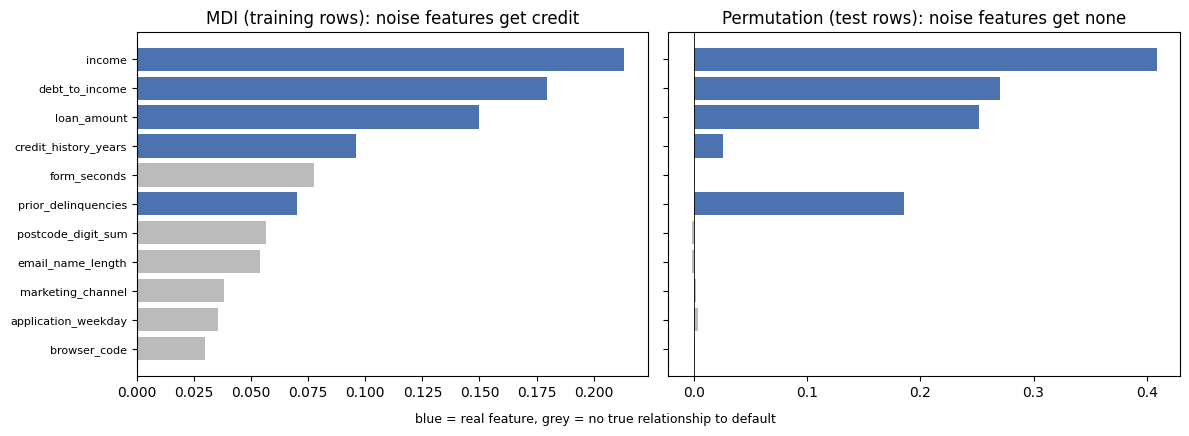

In [14]:
# Step 2.2: a random forest (Lab 19), its out-of-bag score, and two kinds of importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]
rf_test_acc = metrics.accuracy_score(y_test, (rf_prob >= 0.5).astype(int))
print(f"out-of-bag accuracy (no test data used): {rf.oob_score_:.4f}")
print(f"test-set accuracy                       : {rf_test_acc:.4f}   (difference {rf_test_acc - rf.oob_score_:+.4f})")
print(f"standard error of an accuracy measured on {len(y_test):,} rows: {np.sqrt(rf_test_acc * (1 - rf_test_acc) / len(y_test)):.4f}")

# forest against the penalised logistic model on the test set
lg_prob = penalised.predict_proba(X_test)[:, 1]
lg_test_acc = metrics.accuracy_score(y_test, (lg_prob >= 0.5).astype(int))
cmp = pd.DataFrame({
    "accuracy": [lg_test_acc, rf_test_acc],
    "log loss": [metrics.log_loss(y_test, lg_prob), metrics.log_loss(y_test, rf_prob)],
    "ROC AUC": [metrics.roc_auc_score(y_test, lg_prob), metrics.roc_auc_score(y_test, rf_prob)],
    "PR AUC": [metrics.average_precision_score(y_test, lg_prob), metrics.average_precision_score(y_test, rf_prob)]},
    index=[f"{penalised_name} logistic", "random forest"])
print("\ntest set:\n" + cmp.round(4).to_string())
print(f"null model accuracy for reference: {null_acc:.4f}")

# importance: built-in (MDI, computed on the training rows) against permutation importance (on the test rows, PR AUC)
mdi = pd.Series(rf.feature_importances_, index=X_train.columns)
perm = permutation_importance(rf, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_train.columns)
imp = pd.DataFrame({"MDI": mdi, "MDI rank": mdi.rank(ascending=False).astype(int),
                    "permutation": perm_imp, "permutation rank": perm_imp.rank(ascending=False).astype(int),
                    "distinct values": X_train.nunique(), "real?": [c in REAL for c in X_train.columns]}).sort_values("MDI", ascending=False)
print("\nimportances:\n" + imp.round(4).to_string())
noise_mdi_share = imp.loc[~imp["real?"], "MDI"].sum()
print(f"\nshare of total MDI given to the {len(IRRELEVANT)} irrelevant features: {noise_mdi_share:.1%}; "
      f"largest permutation importance among them: {imp.loc[~imp['real?'], 'permutation'].max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
order = imp.sort_values("MDI").index
cols = ["#4C72B0" if imp.loc[c, "real?"] else "#BBBBBB" for c in order]
ax[0].barh(order, imp.loc[order, "MDI"], color=cols); ax[0].set_title("MDI (training rows): noise features get credit")
ax[1].barh(order, imp.loc[order, "permutation"], color=cols); ax[1].set_title("Permutation (test rows): noise features get none")
ax[1].axvline(0, color="black", lw=0.6)
for a_ in ax: a_.tick_params(axis="y", labelsize=8)
fig.text(0.5, -0.02, "blue = real feature, grey = no true relationship to default", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

**Out-of-bag against test.** The forest's out-of-bag accuracy is 0.9433 and its test accuracy 0.9473, a difference of 0.0040. They should be close because the out-of-bag score is itself a held-out estimate: every row is scored only by the trees that never saw it, so no row is marked by a tree that memorised it. The gap here is about one standard error of an accuracy measured on 3,000 rows (0.0041), so it is noise. If the two were far apart it would mean the forest was being scored on something it had seen, or that the test rows come from a different population from the training rows (distribution shift), or that the test sample is too small to trust.

**Forest against the penalised logistic model.** On the test set the forest has accuracy 0.9473 against 0.9460, ROC AUC 0.927 against 0.922, PR AUC 0.612 against 0.593, and a *worse* log loss (0.148 against 0.147). On these numbers the forest is ahead by a hair on three measures and behind on the one that scores probabilities, and I would call it **no clear win**: 500 trees that cannot be shown to beat a handful of coefficients. The lender would have to explain the forest to a regulator, and the simple model is the one it can explain. This verdict rests on two accuracy figures and no test, and Task 4.1 Part A puts a test to it.

**Importance is not effect.** Both measures are in the table and charts above. They disagree sharply. By MDI (computed from the training rows) the six irrelevant features take 29.1% of all importance, and `form_seconds`, which has no relationship to default, ranks 5th, *above* `prior_delinquencies`, which ranks 6th. By permutation importance (computed on the test rows, scored by PR AUC) `prior_delinquencies` is 4th with 0.185, and `form_seconds` is 9th with 0.0007, and the largest permutation importance among all six irrelevant features is 0.0037. MDI inflates high-cardinality features: `form_seconds` has 7,000 distinct values, so a tree has thousands of candidate split points to try, and a split that lowers the training impurity by chance counts as importance. `prior_delinquencies` has 5 values and so few places to split, which understates it. Permutation importance asks what happens to the held-out score when a feature is scrambled, and noise features score near zero.

**Importance is not a lever.** A feature can matter to a prediction and still be useless for changing an outcome, because the model describes who defaults, not what would make them default less. `credit_history_years` is important (0.025) and cannot be changed by declining: the lender cannot lengthen an applicant's credit history. The feature where the distinction changes what the lender should do is `loan_amount`: it is important (0.251, third), and it is the one input the lender controls. For a risky applicant the lender can offer a smaller loan instead of declining, which no ranking of `income` or `prior_delinquencies` allows. Even then the model only shows that applicants who ask for more default more, not that cutting the loan would stop it; a pilot would be needed before treating it as a lever.

## Phase 3: The Number That Actually Matters

### Step 3.1: Beyond accuracy

Ridge logistic, threshold 0.5, 3,000 test applications
confusion matrix (rows = truth, columns = flagged):
   approved good  2762   declined good    29
   approved bad    133   declined bad     76
   accuracy                    0.9460
   precision                   0.7238
   recall                      0.3636
   F1                          0.4841
   ROC AUC                     0.9224
   PR AUC (average precision)  0.5929
   default rate (PR baseline)  0.0697

the null model scores accuracy 0.9303; this model 0.9460, a gain of +0.0157
against the null model the rows that differ are the 76 defaulters caught and the 29 good applicants declined; exact binomial test of 76 against 105: p = 5.1e-06
PR AUC 0.5929 is 8.5 times the default rate 0.0697
at 0.5: false positive rate 0.0104 (looks tiny) but precision 0.7238: 29 of 105 declined applicants were good
at recall 0.8 the ROC curve shows a false positive rate of only 0.127, yet that means about 355 false alarms for 167 hits: precision 0.320

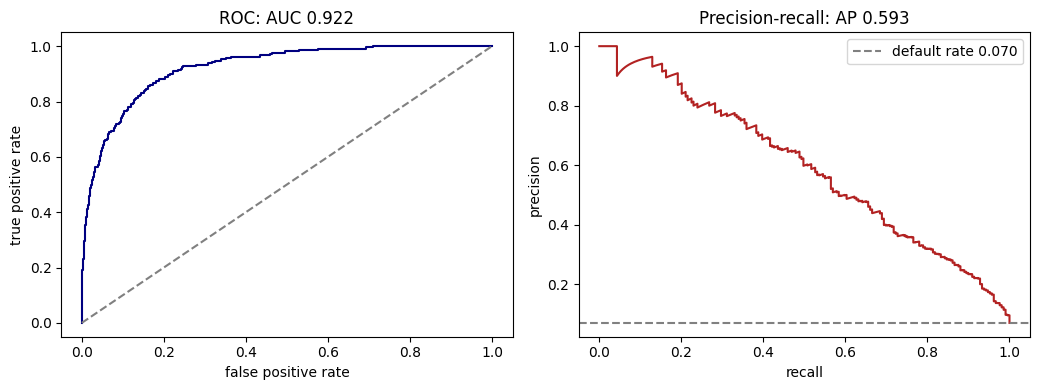

In [15]:
# Step 3.1: beyond accuracy. The test set, my penalised logistic model at the default threshold of 0.5
lg_prob = penalised.predict_proba(X_test)[:, 1]
lg_pred = (lg_prob >= 0.5).astype(int)
tn, fp, fn, tp = metrics.confusion_matrix(y_test, lg_pred, labels=[0, 1]).ravel()
print(f"{penalised_name} logistic, threshold 0.5, {len(y_test):,} test applications")
print(f"confusion matrix (rows = truth, columns = flagged):\n   approved good {tn:>5}   declined good {fp:>5}\n   approved bad  {fn:>5}   declined bad  {tp:>5}")
prevalence = y_test.mean()
res = {"accuracy": metrics.accuracy_score(y_test, lg_pred), "precision": metrics.precision_score(y_test, lg_pred),
       "recall": metrics.recall_score(y_test, lg_pred), "F1": metrics.f1_score(y_test, lg_pred),
       "ROC AUC": metrics.roc_auc_score(y_test, lg_prob), "PR AUC (average precision)": metrics.average_precision_score(y_test, lg_prob)}
for k, v in res.items(): print(f"   {k:<28}{v:.4f}")
print(f"   {'default rate (PR baseline)':<28}{prevalence:.4f}")
print(f"\nthe null model scores accuracy {null_acc:.4f}; this model {res['accuracy']:.4f}, a gain of {res['accuracy'] - null_acc:+.4f}")
from scipy.stats import binomtest
print(f"against the null model the rows that differ are the {tp} defaulters caught and the {fp} good applicants declined; "
      f"exact binomial test of {tp} against {tp + fp}: p = {binomtest(tp, tp + fp, 0.5).pvalue:.1e}")
print(f"PR AUC {res['PR AUC (average precision)']:.4f} is {res['PR AUC (average precision)'] / prevalence:.1f} times the default rate {prevalence:.4f}")

# why ROC AUC flatters: false positive rate divides by the many good applicants
fpr_at, tpr_at = fp / (fp + tn), tp / (tp + fn)
print(f"at 0.5: false positive rate {fpr_at:.4f} (looks tiny) but precision {res['precision']:.4f}: {fp} of {fp + tp} declined applicants were good")
fpr, tpr, _ = metrics.roc_curve(y_test, lg_prob)
j = np.argmin(np.abs(tpr - 0.8))
n_neg, n_pos = int((y_test == 0).sum()), int((y_test == 1).sum())
tp_8, fp_8 = tpr[j] * n_pos, fpr[j] * n_neg
print(f"at recall 0.8 the ROC curve shows a false positive rate of only {fpr[j]:.3f}, yet that means about {fp_8:.0f} false alarms for {tp_8:.0f} hits: precision {tp_8 / (tp_8 + fp_8):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
ax[0].plot(fpr, tpr, color="navy"); ax[0].plot([0, 1], [0, 1], ls="--", color="gray")
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title=f"ROC: AUC {res['ROC AUC']:.3f}")
pc, rc, _ = metrics.precision_recall_curve(y_test, lg_prob)
ax[1].plot(rc, pc, color="firebrick"); ax[1].axhline(prevalence, ls="--", color="gray", label=f"default rate {prevalence:.3f}")
ax[1].set(xlabel="recall", ylabel="precision", title=f"Precision-recall: AP {res['PR AUC (average precision)']:.3f}"); ax[1].legend()
plt.tight_layout(); plt.show()

**Why ROC AUC flatters at 7% prevalence.** The ROC curve's x-axis, the false positive rate, divides the false alarms by *all* good applicants, and at 7% prevalence there are 2,791 of them against 209 defaulters. So a false positive rate that looks small still produces a lot of false alarms in absolute terms. At recall 0.8 the ROC curve is at a false positive rate of 0.127, which sounds fine, but it means about 355 false alarms for 167 hits: a precision of only 0.320. **The precision-recall curve is the more honest picture** because precision divides by what the lender actually acts on, the applicants it declines, so false alarms cannot hide behind the large denominator. A random model would sit at the default rate (0.0697) on that chart, and this model's PR AUC of 0.5929 is 8.5 times that baseline: a good model, and much less impressive than an ROC AUC of 0.922 alone suggests.

### Step 3.2: Put a price on being wrong

false negative costs 60% of principal; false positive costs 10% (8% margin + 2% reputation); ratio 6:1
closed-form threshold if probabilities are right: 0.10 / (0.10 + 0.60) = 0.1429

cost-minimising threshold on the training rows: 0.201, which is 0.299 below the default 0.5
                        threshold  declined   TP   FP   FN    TN  recall  precision  cost per app ($)
default 0.5                 0.500       105   76   29  133  2762   0.364      0.724           481.091
chosen (training rows)      0.201       330  144  186   65  2605   0.689      0.436           328.197
closed form                 0.143       422  153  269   56  2522   0.732      0.363           346.464

reference, test set, dollars per application: approve everyone 790.7; decline everyone 1,330.3
adopting 0.201 instead of 0.5 saves 152.9 per application on the test set (32% of the cost at 0.5), 458,682 dollars over the 3,000 test applications
and against approving everyone (the null model) it saves 462.5 per appl

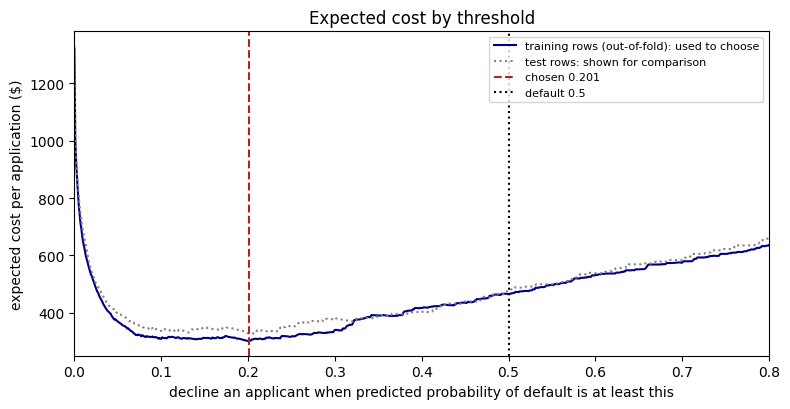


how the optimal threshold moves with the cost ratio (FN fixed at 60% of principal):
FN:FP ratio FP cost  closed form  chosen threshold  share declined  cost at 0.5 ($)  cost at chosen ($)
       20:1      3%        0.048             0.046           0.275          463.508             169.489
       12:1      5%        0.077             0.071           0.221          468.532             228.599
        6:1     10%        0.143             0.201           0.110          481.091             328.197
        4:1     15%        0.200             0.237           0.094          493.650             394.675
        3:1     20%        0.250             0.272           0.082          506.209             449.843
        2:1     30%        0.333             0.298           0.076          531.328             520.558


In [16]:
# Step 3.2: put a price on being wrong. Costs are shares of the loan's principal.
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.base import clone

LGD = 0.60            # a default loses 60% of principal
MARGIN = 0.08         # a declined good applicant loses the expected interest margin, 8% of principal
REPUTATION = 0.02     # plus a reputational cost, stated and justified in the text below
FN_COST, FP_COST = LGD, MARGIN + REPUTATION
closed_form = FP_COST / (FP_COST + FN_COST)
print(f"false negative costs {FN_COST:.0%} of principal; false positive costs {FP_COST:.0%} ({MARGIN:.0%} margin + {REPUTATION:.0%} reputation); ratio {FN_COST / FP_COST:.0f}:1")
print(f"closed-form threshold if probabilities are right: {FP_COST:.2f} / ({FP_COST:.2f} + {FN_COST:.2f}) = {closed_form:.4f}")

def expected_cost(prob, y, loan, thresholds, fn_cost=FN_COST, fp_cost=FP_COST):
    """Average cost per application, in dollars, of declining every applicant whose probability is at or above each threshold."""
    y, loan = np.asarray(y), np.asarray(loan)
    out = np.empty(len(thresholds))
    for k, t in enumerate(thresholds):
        flag = prob >= t
        out[k] = (fn_cost * loan[(y == 1) & ~flag].sum() + fp_cost * loan[(y == 0) & flag].sum()) / len(y)
    return out

ts = np.round(np.linspace(0, 1, 1001), 3)                   # every threshold from 0 to 1
# choose the threshold on out-of-fold probabilities for the TRAINING rows, then price it once on the test rows
oof = cross_val_predict(clone(penalised), X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
cost_train = expected_cost(oof, y_train, X_train["loan_amount"], ts)
cost_test = expected_cost(lg_prob, y_test, X_test["loan_amount"], ts)       # shown for comparison, never used to choose
best_t = ts[np.argmin(cost_train)]

def at(t, prob=lg_prob):
    flag = prob >= t
    tn_, fp_, fn_, tp_ = metrics.confusion_matrix(y_test, flag.astype(int), labels=[0, 1]).ravel()
    return {"threshold": t, "declined": int(flag.sum()), "TP": tp_, "FP": fp_, "FN": fn_, "TN": tn_,
            "recall": tp_ / (tp_ + fn_), "precision": tp_ / max(tp_ + fp_, 1),
            "cost per app ($)": expected_cost(prob, y_test, X_test["loan_amount"], [t])[0]}
compare = pd.DataFrame([at(0.5), at(best_t), at(closed_form)], index=["default 0.5", "chosen (training rows)", "closed form"])
decline_all = expected_cost(np.ones(len(y_test)), y_test, X_test["loan_amount"], [0.5])[0]
approve_all = expected_cost(np.zeros(len(y_test)), y_test, X_test["loan_amount"], [0.5])[0]
print(f"\ncost-minimising threshold on the training rows: {best_t:.3f}, which is {0.5 - best_t:.3f} below the default 0.5")
print(compare.round(3).to_string())
print(f"\nreference, test set, dollars per application: approve everyone {approve_all:,.1f}; decline everyone {decline_all:,.1f}")
saving = compare.loc["default 0.5", "cost per app ($)"] - compare.loc["chosen (training rows)", "cost per app ($)"]
total_saving = saving * len(y_test)
print(f"adopting {best_t:.3f} instead of 0.5 saves {saving:,.1f} per application on the test set ({saving / compare.loc['default 0.5', 'cost per app ($)']:.0%} of the cost at 0.5), "
      f"{total_saving:,.0f} dollars over the {len(y_test):,} test applications")
print(f"and against approving everyone (the null model) it saves {approve_all - compare.loc['chosen (training rows)', 'cost per app ($)']:,.1f} per application "
      f"({1 - compare.loc['chosen (training rows)', 'cost per app ($)'] / approve_all:.0%})")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ts, cost_train, color="navy", label="training rows (out-of-fold): used to choose")
ax.plot(ts, cost_test, color="gray", ls=":", label="test rows: shown for comparison")
ax.axvline(best_t, color="firebrick", ls="--", label=f"chosen {best_t:.3f}"); ax.axvline(0.5, color="black", ls=":", label="default 0.5")
ax.set(xlabel="decline an applicant when predicted probability of default is at least this", ylabel="expected cost per application ($)", xlim=(0, 0.8))
ax.legend(fontsize=8); ax.set_title("Expected cost by threshold"); plt.tight_layout(); plt.show()

# how the optimal threshold moves with the cost ratio: hold the false negative at 60% and vary the false positive cost
sens = []
for fp_c in (0.03, 0.05, 0.10, 0.15, 0.20, 0.30):
    t_i = ts[np.argmin(expected_cost(oof, y_train, X_train["loan_amount"], ts, fp_cost=fp_c))]
    r_i = at(t_i)
    r_i0 = expected_cost(lg_prob, y_test, X_test["loan_amount"], [0.5], fp_cost=fp_c)[0]
    r_it = expected_cost(lg_prob, y_test, X_test["loan_amount"], [t_i], fp_cost=fp_c)[0]
    sens.append({"FN:FP ratio": f"{LGD / fp_c:.0f}:1", "FP cost": f"{fp_c:.0%}", "closed form": fp_c / (fp_c + LGD), "chosen threshold": t_i,
                 "share declined": r_i["declined"] / len(y_test), "cost at 0.5 ($)": r_i0, "cost at chosen ($)": r_it})
sens = pd.DataFrame(sens)
print("\nhow the optimal threshold moves with the cost ratio (FN fixed at 60% of principal):")
print(sens.round(3).to_string(index=False))

**The costs and where they come from.** Costs are shares of the loan's principal. A false negative, a loan that defaults, loses 60% of principal. A false positive, a good applicant declined, loses the expected interest margin (8% of principal) **plus a reputational cost I set at 2% of principal**, so 10% in all. That is a quarter of the margin, and I justify it as the value of the *next* loan: a good customer who is turned down tends to take the next loan elsewhere, and a decline also costs complaint handling and attracts fair-lending scrutiny. It is an assumption, so the sensitivity table varies it from 3% to 30%. The ratio is 6 to 1, so a probability of default above 0.10 / (0.10 + 0.60) = 0.1429 makes declining the cheaper mistake **if the probabilities are right**. The loan amount cancels out of that comparison, so the threshold applies to loans of every size; the dollar costs below weight each application by its own principal.

**The expected-cost curve.** The cost of every threshold from 0 to 1 is in the chart above. The threshold is chosen on the *training* rows, using out-of-fold probabilities, and priced once on the test rows (the dotted test curve is shown for comparison and was not used to choose). **The cost-minimising threshold is 0.201, which is 0.299 below the default of 0.5.**

**What adopting it does.** At 0.5 the model declines 105 test applicants: 76 caught, 29 good declined, 133 defaulters approved, at a cost of 481.1 dollars per application. At 0.201 it declines 330: 144 caught, 186 good declined, 65 defaulters approved, at 328.2 dollars. So it catches 68 more defaulters and declines 157 more good applicants: a price worth paying because a missed default costs six times as much. That saves 152.9 dollars per application (32% of the cost at 0.5), $458,682 over the 3,000 test applications. Against the null model, which approves everyone and costs 790.7 dollars per application, the chosen threshold saves 58%. Note that the cost curve is **flat** between about 0.1 and 0.25 (the chart): the closed-form 0.143 costs 346.5 dollars per application against 328.2 dollars, a difference too small to say which is better, so the choice within that range is not sharp.

**How the optimal threshold moves with the cost ratio** (table above, the false negative held at 60% and the false positive cost varied): the chosen threshold falls from 0.298 at 2:1 to 0.046 at 20:1, tracking the closed form (0.333 to 0.048) to within a few hundredths. **The rule for the head of risk: decline an application when the model's probability of default is above 1 / (1 + r), where r is how many times worse a missed default is than a wrongly declined good applicant.** At r = 6 that is about 14%; at r = 12, about 8%; at r = 20, about 5%; if declining a good customer is judged as costly as missing a default, 50%, which is the 0.5 the software starts with. Take r from finance and credit policy, not from the data.

## Phase 4: AI Expansion — The Co-Pilot Era

### Task 4.1: Two claims you already made, now tested

#### Part A: Does the forest actually beat the logistic model?

In [17]:
# Task 4.1 Part A: does the forest actually beat the penalised logistic model? McNemar's test on the paired predictions
from scipy.stats import binomtest, chi2

rf_pred = (rf_prob >= 0.5).astype(int)
lg_pred = (lg_prob >= 0.5).astype(int)
yt = np.asarray(y_test)
rf_right, lg_right = rf_pred == yt, lg_pred == yt
a = int((rf_right & lg_right).sum()); b = int((rf_right & ~lg_right).sum()); c = int((~rf_right & lg_right).sum()); d = int((~rf_right & ~lg_right).sum())
print(f"accuracy: forest {rf_right.mean():.4f}, {penalised_name} logistic {lg_right.mean():.4f}, difference {rf_right.mean() - lg_right.mean():+.4f}  ({int(rf_right.sum()) - int(lg_right.sum()):+d} rows)")
print("\n2x2 table of agreement (rows = forest, columns = logistic):")
print(f"                logistic right   logistic wrong\n   forest right  {a:>10}   {b:>10}   <- b: forest right, logistic wrong\n   forest wrong  {c:>10}   {d:>10}   <- c: forest wrong, logistic right")
print(f"\nb = {b}, c = {c}, b + c = {b + c} discordant rows out of {len(yt):,}; the other {a + d:,} say nothing about which model is better")

exact = binomtest(b, b + c, 0.5)                          # exact: under the null a discordant row falls either way with probability 1/2
stat = (abs(b - c) - 1) ** 2 / (b + c)                    # continuity-corrected chi-square, 1 degree of freedom
p_chi = chi2.sf(stat, df=1)
print(f"exact binomial test of b against b + c: p = {exact.pvalue:.4f}")
print(f"continuity-corrected McNemar chi-square: {stat:.3f}, p = {p_chi:.4f}   (for comparison)")
test_used = "exact binomial" if b + c < 25 else "continuity-corrected chi-square"
print(f"test used: {test_used}, because b + c = {b + c}")

# the independent-samples test the usual reply reaches for, shown only to see what it would have said
p1, p2, n1 = rf_right.mean(), lg_right.mean(), len(yt)
pooled = (p1 + p2) / 2; z = (p1 - p2) / np.sqrt(2 * pooled * (1 - pooled) / n1)
print(f"a two-proportion z-test (wrongly treats the two accuracies as independent): z = {z:.3f}, p = {2 * stats.norm.sf(abs(z)):.4f}")

# the comparison that matches the decision: a paired bootstrap of PR AUC, resampling test rows
from sklearn import metrics
rs = np.random.default_rng(RANDOM_STATE); diffs = []
for _ in range(1000):
    idx = rs.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0: continue
    diffs.append(metrics.average_precision_score(yt[idx], rf_prob[idx]) - metrics.average_precision_score(yt[idx], lg_prob[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
ap_diff = metrics.average_precision_score(yt, rf_prob) - metrics.average_precision_score(yt, lg_prob)
print(f"\npaired bootstrap (1,000 resamples of test rows), PR AUC forest minus logistic: {ap_diff:+.4f}, 95% interval [{lo:+.4f}, {hi:+.4f}]")

accuracy: forest 0.9473, Ridge logistic 0.9460, difference +0.0013  (+4 rows)

2x2 table of agreement (rows = forest, columns = logistic):
                logistic right   logistic wrong
   forest right        2810           32   <- b: forest right, logistic wrong
   forest wrong          28          130   <- c: forest wrong, logistic right

b = 32, c = 28, b + c = 60 discordant rows out of 3,000; the other 2,940 say nothing about which model is better
exact binomial test of b against b + c: p = 0.6989
continuity-corrected McNemar chi-square: 0.150, p = 0.6985   (for comparison)
test used: continuity-corrected chi-square, because b + c = 60
a two-proportion z-test (wrongly treats the two accuracies as independent): z = 0.230, p = 0.8182

paired bootstrap (1,000 resamples of test rows), PR AUC forest minus logistic: +0.0195, 95% interval [-0.0316, +0.0669]


**The test and its assumption.** The usual reply to the prompt compares two accuracies as if they came from two independent samples (a two-proportion z-test, or `ttest_ind`), which assumes the two sets of predictions are independent. Mine are not: both models predicted the **same 3,000 test rows**, so the predictions are paired, and the evidence is in the rows where the models disagree. The z-test, which ignores the pairing, would have said z = 0.230, p = 0.818. I used **McNemar's test**. Of the 3,000 rows, 2,940 are rows both models get right or both get wrong and say nothing about which is better. **b = 32** (forest right, logistic wrong), **c = 28** (forest wrong, logistic right), **b + c = 60**. Because b + c is 60, above the usual cutoff of 25 for the exact test, I used the continuity-corrected chi-square (0.150), **p = 0.699**; the exact binomial test of 32 against 60 agrees (p = 0.699).

**Does my Step 2.2 verdict survive?** Yes. In Step 2.2 I called the forest's lead a hair, no clear win, from two accuracy figures (0.9473 against 0.9460, a difference of 4 rows). The test confirms it: the forest's 32 wins against the logistic model's 28 are indistinguishable from a coin flip (p = 0.70). Had I written "the forest is better" from those accuracies, the verdict would not have survived. An expensive model that cannot be shown to beat a cheap one is the finding the lender needs.

**One limitation.** At 7% prevalence accuracy is the wrong quantity (Phase 3), so McNemar on accuracy tests whether the two models differ in *error count*, which is not what the lender pays for. The comparison that would match the decision is a paired comparison on the cost-weighted outcome or on PR AUC, resampling test rows rather than treating them as independent. As a check I ran the PR AUC version: the forest's PR AUC is 0.0195 higher, with a 95% interval of [-0.0316, 0.0669] that includes zero, so it points the same way.

#### Part B: Is your Phase 3 threshold valid?

                Brier  reliability  resolution  uncertainty  remainder     ECE  log loss  ROC AUC
version                                                                                          
raw           0.04170      0.00004     0.01830      0.06481   -0.00486 0.00471   0.14728  0.92243
Platt scaling 0.04170      0.00004     0.01830      0.06481   -0.00486 0.00454   0.14728  0.92243
isotonic      0.04212      0.00015     0.01892      0.06481   -0.00392 0.00645   0.14785  0.92228
share of test applications with a predicted probability below 0.1: 82.2% (so equal-width bins would put most rows in the first bin and leave the high bins nearly empty)

reliability table, raw probabilities (10 quantile bins; Wilson 95% interval on the observed rate):
                                   n     mean_p    obs  defaults         lo     hi
bin                                                                               
(-0.0009999999999528, 0.000195]  300  1.000e-04  0.000         0  0.000e+00

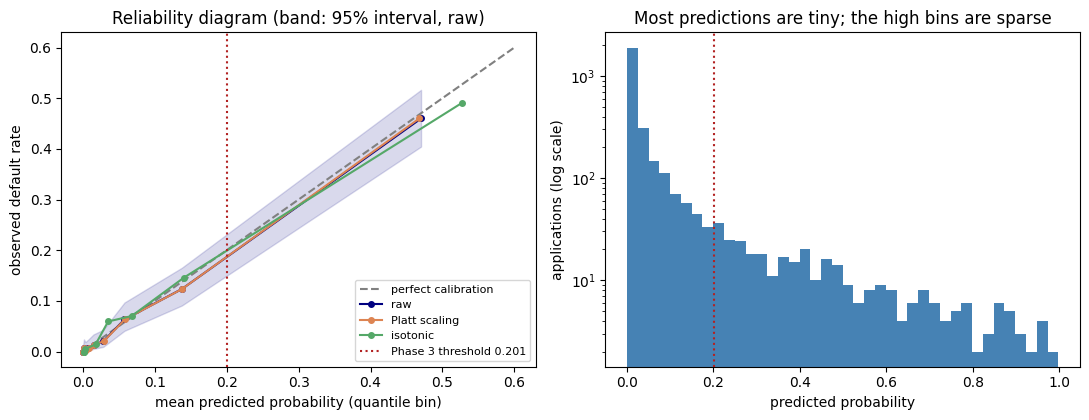


applications with predicted probability within 0.04 of the threshold 0.201: 111; mean predicted 0.1985; observed default rate 0.1532, 95% interval [0.0979, 0.2316]

threshold recomputed on calibrated probabilities:
               threshold  cost per app ($)  declined
version                                             
raw (Phase 3)      0.201           328.197       330
Platt scaling      0.200           328.197       330
isotonic           0.131           328.197       330
closed-form threshold (needs calibrated probabilities): 0.1429


In [18]:
# Task 4.1 Part B: is the Phase 3 threshold valid? Calibration of the penalised logistic model
from sklearn.isotonic import IsotonicRegression

def wilson(k, n, z=1.96):
    p = k / n; centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

def calibration_table(prob, y, bins=10):
    """Quantile bins, so every bin holds about the same number of rows even when most probabilities are tiny."""
    q = pd.qcut(prob, bins, duplicates="drop")
    t = pd.DataFrame({"p": prob, "y": np.asarray(y), "bin": q}).groupby("bin", observed=True).agg(n=("y", "size"), mean_p=("p", "mean"), obs=("y", "mean"), defaults=("y", "sum"))
    t["lo"], t["hi"] = zip(*[wilson(k, n) for k, n in zip(t["defaults"], t["n"])])
    return t

def brier_parts(prob, y, bins=10):
    """Brier score, and the binned decomposition: reliability - resolution + uncertainty."""
    t = calibration_table(prob, y, bins); w = t["n"] / t["n"].sum(); base = np.mean(y)
    rel = np.sum(w * (t["mean_p"] - t["obs"]) ** 2); res = np.sum(w * (t["obs"] - base) ** 2); unc = base * (1 - base)
    return metrics.brier_score_loss(y, prob), rel, res, unc

def ece(prob, y, bins=10):
    t = calibration_table(prob, y, bins); return np.sum(t["n"] / t["n"].sum() * (t["mean_p"] - t["obs"]).abs())

# calibrators are fitted on the training rows' out-of-fold probabilities (never on the test rows)
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(oof).reshape(-1, 1), y_train)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof, y_train)
versions = {"raw": lg_prob, "Platt scaling": platt.predict_proba(logit(lg_prob).reshape(-1, 1))[:, 1], "isotonic": iso.predict(lg_prob)}

rows = []
for name, pr in versions.items():
    bs, rel, resol, unc = brier_parts(pr, y_test)
    rows.append({"version": name, "Brier": bs, "reliability": rel, "resolution": resol, "uncertainty": unc, "remainder": bs - (rel - resol + unc), "ECE": ece(pr, y_test),
                 "log loss": metrics.log_loss(y_test, np.clip(pr, 1e-6, 1 - 1e-6)), "ROC AUC": metrics.roc_auc_score(y_test, pr)})
cal = pd.DataFrame(rows).set_index("version")
print(cal.to_string(float_format="{:.5f}".format))

raw_t = calibration_table(lg_prob, y_test)
share_low = (lg_prob < 0.1).mean()
print(f"share of test applications with a predicted probability below 0.1: {share_low:.1%} (so equal-width bins would put most rows in the first bin and leave the high bins nearly empty)")
print("\nreliability table, raw probabilities (10 quantile bins; Wilson 95% interval on the observed rate):")
print(raw_t.round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].plot([0, 0.6], [0, 0.6], ls="--", color="gray", label="perfect calibration")
for name, colr in [("raw", "navy"), ("Platt scaling", "#DD8452"), ("isotonic", "#55A868")]:
    t_ = calibration_table(versions[name], y_test)
    ax[0].plot(t_["mean_p"], t_["obs"], "o-", color=colr, label=name, ms=4)
    if name == "raw": ax[0].fill_between(t_["mean_p"], t_["lo"], t_["hi"], color=colr, alpha=0.15)
ax[0].axvline(best_t, color="firebrick", ls=":", label=f"Phase 3 threshold {best_t:.3f}")
ax[0].set(xlabel="mean predicted probability (quantile bin)", ylabel="observed default rate", title="Reliability diagram (band: 95% interval, raw)"); ax[0].legend(fontsize=8)
ax[1].hist(lg_prob, bins=40, color="steelblue"); ax[1].set_yscale("log"); ax[1].axvline(best_t, color="firebrick", ls=":")
ax[1].set(xlabel="predicted probability", ylabel="applications (log scale)", title="Most predictions are tiny; the high bins are sparse")
plt.tight_layout(); plt.show()

# is the threshold valid? Look where the decision is made: applications whose probability sits near the threshold
band = (lg_prob >= best_t - 0.04) & (lg_prob <= best_t + 0.04)
k_, n_ = int(np.asarray(y_test)[band].sum()), int(band.sum()); lo_b, hi_b = wilson(k_, n_)
print(f"\napplications with predicted probability within 0.04 of the threshold {best_t:.3f}: {n_}; mean predicted {lg_prob[band].mean():.4f}; observed default rate {k_ / n_:.4f}, 95% interval [{lo_b:.4f}, {hi_b:.4f}]")
# recompute the threshold on calibrated probabilities (fitted on out-of-fold training probabilities)
oof_cal = {"Platt scaling": platt.predict_proba(logit(oof).reshape(-1, 1))[:, 1], "isotonic": iso.predict(oof)}
out = []
for name in ("Platt scaling", "isotonic"):
    t_cal = ts[np.argmin(expected_cost(oof_cal[name], y_train, X_train["loan_amount"], ts))]
    out.append({"version": name, "threshold": t_cal, "cost per app ($)": expected_cost(versions[name], y_test, X_test["loan_amount"], [t_cal])[0],
                "declined": int((versions[name] >= t_cal).sum())})
out.insert(0, {"version": "raw (Phase 3)", "threshold": best_t, "cost per app ($)": expected_cost(lg_prob, y_test, X_test["loan_amount"], [best_t])[0], "declined": int((lg_prob >= best_t).sum())})
recal = pd.DataFrame(out).set_index("version"); print("\nthreshold recomputed on calibrated probabilities:\n" + recal.round(4).to_string())
print(f"closed-form threshold (needs calibrated probabilities): {closed_form:.4f}")

**The check.** Overall the Ridge model is well calibrated: Brier score 0.0417, reliability term 4.4e-05 (the part of the Brier score due to miscalibration; near zero is good; the binned decomposition is approximate, and the remainder column is the within-bin variance it leaves out), expected calibration error 0.0047. The reliability diagram follows the diagonal. Because most applicants have a tiny probability, I used **quantile bins** (82% of the applications have a predicted probability below 0.1, so equal-width bins would put most rows in the first bin and leave the high bins almost empty), so each of the ten bins holds 300 applications, and I drew a Wilson 95% interval on each observed rate. The top bin averages 0.470 predicted and 0.460 observed.

**Does calibrating help?** No. Platt scaling gives the same Brier score (0.0417) and calibration error (0.0045), because the model is already calibrated in aggregate. Isotonic regression is slightly *worse* (0.15 against 0.04 in thousandths on the reliability term), because its steps follow noise in a sparse sample. Neither changes the ROC AUC (0.922): calibration is a monotone re-labelling of the probabilities.

**Why a model can rank well and still be badly calibrated, and why that decides the threshold.** AUC only asks whether defaulters tend to get higher scores than good applicants; a model whose probabilities are all twice too high, or squashed towards the middle, ranks exactly as well. The cost-optimal threshold, though, is a statement about probability: decline when the *probability* of default exceeds 0.143. If the scores are not probabilities, that cut-off is in the wrong place, however high the AUC.

**Does my Phase 3 threshold survive?** The decision survives, and its meaning needs care. Platt scaling leaves it essentially where it was (0.200 against 0.201) and all three versions decline the same 330 applicants at the same cost, because a monotone re-labelling does not change who is above the cut. What changes is what the number means. On the raw scale the cost-minimising threshold is 0.201, well above the closed-form 0.143, and the reliability diagram shows why: the 111 applications with a predicted probability within 0.04 of the threshold had a mean prediction of 0.198 and an observed default rate of 0.153, so the model overstates the risk a little where the decision is made (the interval, [0.098, 0.232], is wide, and includes the prediction). **Recomputed on isotonic-calibrated probabilities the threshold is 0.131**, much closer to the closed form. So I report both: **0.201 on the model's raw scores and 0.131 on calibrated probabilities**; they pick out the same applicants. Before using the threshold as a statement about risk ("decline above 20% default probability" would be wrong; the risk at the cut is about 13 to 15%), the lender should quote the calibrated one or the closed form.

### Task 4.2: The recommendation

**To the head of risk: sign, but not on the vendor's number.** Approving every applicant scores 0.930 accuracy on our test set, so a "93%" proves nothing. The model scores 0.946, a gain of under two points that hides what matters, which is money.

**Worth against the null.** Approving everyone costs 791 dollars per application in losses; the model at the default 0.5 cutoff costs $481; at the cutoff I recommend it costs 328 dollars, 58% below the null. It declines 330 of 3,000, catching 144 of 209 defaulters and declining 186 good applicants.

**Threshold and assumptions.** Decline when predicted default probability is at least **0.20**. Assumptions: a default loses 60% of principal; a declined good applicant costs 10% (8% margin plus 2% reputation), a 6:1 ratio. The rule is to decline above 1 / (1 + ratio). The cost curve is flat: 0.14 costs $346, so anything from 0.14 to 0.20 is defensible.

**Do not pay extra for the forest:** it ties the simple model (McNemar p = 0.70).

**What would change my answer:** a production default rate far from 7%. The probabilities, and the cutoff, are only as good as that match; check calibration on the first three months of live loans.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's reply **exactly as it came back**, unedited and before your corrections, then one line on each change you made. Name the model and the date.

**Part A: does the forest actually beat the logistic model?**

*Model and date:* ChatGPT 11/24/2026
*Prompt:*

```
[Prep] Act as a model risk analyst comparing two candidate credit models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The random forest got 0.947 accuracy and the penalised logistic model got 0.946. Write Python that tells me whether the forest is significantly better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.
```

*Reply

```python
import numpy as np  # Numerical calculations
import pandas as pd  # Organising prediction results
from scipy.stats import chi2  # Chi-square distribution for McNemar's test

# Convert the actual outcomes into a NumPy array
y = np.asarray(y_test)

# Convert random forest predictions into a NumPy array
rf = np.asarray(rf_pred)

# Convert logistic regression predictions into a NumPy array
logistic = np.asarray(logistic_pred)

# Check that all three arrays contain the same number of observations
assert len(y) == len(rf) == len(logistic), "Array lengths must match"

# Identify observations correctly classified by the random forest
rf_correct = (rf == y)

# Identify observations correctly classified by logistic regression
logistic_correct = (logistic == y)

# Count observations where both models are correct
both_correct = np.sum(rf_correct & logistic_correct)

# Count observations where both models are incorrect
both_wrong = np.sum(~rf_correct & ~logistic_correct)

# Count observations where only the random forest is correct
rf_only_correct = np.sum(rf_correct & ~logistic_correct)

# Count observations where only logistic regression is correct
logistic_only_correct = np.sum(~rf_correct & logistic_correct)

# Construct the paired prediction comparison table
contingency_table = pd.DataFrame(
    [[both_correct, rf_only_correct],
     [logistic_only_correct, both_wrong]],
    index=["RF Correct", "RF Incorrect"],
    columns=["Logistic Correct", "Logistic Incorrect"]
)

# Display the paired prediction comparison
print("McNemar Contingency Table:")
print(contingency_table)

# Calculate the total number of observations
n = len(y)

# Calculate random forest accuracy
rf_accuracy = np.mean(rf_correct)

# Calculate logistic regression accuracy
logistic_accuracy = np.mean(logistic_correct)

# Calculate the number of discordant prediction pairs
discordant = rf_only_correct + logistic_only_correct

# Apply McNemar's continuity-corrected chi-square statistic
if discordant == 0:
    statistic = 0.0
    p_value = 1.0
else:
    statistic = (
        (abs(rf_only_correct - logistic_only_correct) - 1) ** 2
        / discordant
    )

    # Calculate the two-sided p-value
    p_value = chi2.sf(statistic, df=1)

# Display both models' accuracy
print("\nModel Accuracy:")
print(f"Random Forest: {rf_accuracy:.4f}")
print(f"Logistic Regression: {logistic_accuracy:.4f}")

# Display the difference in accuracy
print(f"Accuracy Difference: {rf_accuracy - logistic_accuracy:.4f}")

# Display the McNemar test statistic
print(f"\nMcNemar Statistic: {statistic:.4f}")

# Display the p-value
print(f"p-value: {p_value:.6f}")

# Interpret statistical significance at the 5% level
if p_value < 0.05:
    print("The difference in model performance is statistically significant.")
else:
    print("There is insufficient evidence of a statistically significant difference.")
```

*One line on each change I made to its code:*

1. Added two lines above the reply's code in the first Part A cell, defining `rf_pred` and `logistic_pred` as my two models' 0/1 predictions at the default 0.5 threshold, because the reply assumes arrays with those names. The rest of that cell is the reply as given.
2. Added a second Part A cell, because the reply's code never prints b + c, always uses the chi-square with no exact binomial fallback for small b + c, and does not say what the test assumes. It prints b, c and b + c, runs the exact binomial test beside the chi-square, and, for contrast, shows the independent-samples z-test that the prompt's omission invites.
3. In that second cell, added a paired bootstrap of PR AUC, the comparison that would match the decision better than an error count.
4. Wrote the statement of what McNemar's test assumes in the text cell, because the reply's comments do not state it.

**Part B: is the Phase 3 threshold valid?**

*Model and date:* ChatGPT 11/24/2026

*Prompt:*

```
[Prep] Act as a model risk analyst at a bank, reviewing a credit scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities on a test set with about 7% prevalence. Write Python that assesses CALIBRATION -- a reliability diagram binning predicted probability against observed frequency, plus the Brier score and its decomposition -- and then applies both Platt scaling and isotonic regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and y_prob. Handle the sparse high-probability bins that low prevalence creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly -- high AUC -- and still be badly calibrated, and why that distinction decides whether the cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold valid? If not, what should I do before using it?
```

*Reply

```python
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss


# -------------------------------------------------------
# 1. Prepare probabilities and create calibration/eval sets
# -------------------------------------------------------

y = np.asarray(y_test).ravel()
p = np.asarray(y_prob).ravel()

# Split existing out-of-sample predictions into two groups.
# One group fits the calibration mappings; the other evaluates them.
# This avoids evaluating a calibrator on the same labels used to fit it.

idx_cal, idx_eval = train_test_split(
    np.arange(len(y)),
    test_size=0.50,
    random_state=42,
    stratify=y
)

y_cal, y_eval = y[idx_cal], y[idx_eval]
p_cal, p_eval = p[idx_cal], p[idx_eval]

# Clip probabilities to avoid infinite logits.
eps = 1e-7
p_cal = np.clip(p_cal, eps, 1 - eps)
p_eval = np.clip(p_eval, eps, 1 - eps)


# -------------------------------------------------------
# 2. Fit Platt scaling and isotonic regression
# -------------------------------------------------------

# Platt scaling: logistic regression on the log-odds of
# the original predicted probabilities.

logit_cal = np.log(p_cal / (1 - p_cal)).reshape(-1, 1)
logit_eval = np.log(p_eval / (1 - p_eval)).reshape(-1, 1)

platt = LogisticRegression()
platt.fit(logit_cal, y_cal)

p_platt = platt.predict_proba(logit_eval)[:, 1]


# Isotonic regression: learns a non-decreasing mapping
# from predicted probabilities to observed outcomes.

isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(p_cal, y_cal)

p_iso = isotonic.predict(p_eval)


# -------------------------------------------------------
# 3. Reliability diagram with adaptive equal-frequency bins
# -------------------------------------------------------

def reliability_stats(y_true, probabilities, n_bins=10,
                      min_bin_size=25):

    order = np.argsort(probabilities)
    n = len(y_true)

    # Reduce the number of bins if the evaluation sample
    # is too small to support the requested bin size.
    n_groups = min(n_bins, max(1, n // min_bin_size))

    groups = np.array_split(order, n_groups)

    mean_predicted = []
    observed_frequency = []
    counts = []

    for group in groups:
        if len(group) == 0:
            continue

        mean_predicted.append(probabilities[group].mean())
        observed_frequency.append(y_true[group].mean())
        counts.append(len(group))

    return (
        np.array(mean_predicted),
        np.array(observed_frequency),
        np.array(counts)
    )


models = {
    "Original": p_eval,
    "Platt Scaling": p_platt,
    "Isotonic Regression": p_iso
}

plt.figure(figsize=(9, 7))

# Perfect calibration reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

for name, probabilities in models.items():

    mean_pred, observed, counts = reliability_stats(
        y_eval, probabilities
    )

    # Marker size reflects the number of observations in each bin.
    plt.scatter(
        mean_pred,
        observed,
        s=30 + 3 * np.sqrt(counts),
        alpha=0.75,
        label=name
    )

    plt.plot(mean_pred, observed, alpha=0.5)

    # Display bin sample sizes to make sparse regions visible.
    for x, y_point, count in zip(mean_pred, observed, counts):
        plt.annotate(
            f"n={count}",
            (x, y_point),
            fontsize=7,
            xytext=(4, 4),
            textcoords="offset points"
        )

plt.xlabel("Mean Predicted Probability of Default")
plt.ylabel("Observed Default Frequency")
plt.title("Credit Scoring Model: Reliability Diagram")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# -------------------------------------------------------
# 4. Brier score decomposition
# -------------------------------------------------------

def brier_decomposition(y_true, probabilities, n_bins=10):

    mean_pred, observed, counts = reliability_stats(
        y_true, probabilities, n_bins=n_bins
    )

    prevalence = np.mean(y_true)
    weights = counts / counts.sum()

    # Reliability: deviation between predicted and observed rates.
    reliability = np.sum(
        weights * (mean_pred - observed) ** 2
    )

    # Resolution: ability to distinguish groups with
    # different observed default frequencies.
    resolution = np.sum(
        weights * (observed - prevalence) ** 2
    )

    # Uncertainty: inherent outcome variability.
    uncertainty = prevalence * (1 - prevalence)

    brier = brier_score_loss(y_true, probabilities)

    # This is the binned Murphy decomposition.
    reconstructed = reliability - resolution + uncertainty

    return {
        "Brier Score": brier,
        "Reliability": reliability,
        "Resolution": resolution,
        "Uncertainty": uncertainty,
        "Binned Reconstruction": reconstructed,
        "Decomposition Gap": brier - reconstructed
    }


# -------------------------------------------------------
# 5. Compare calibration methods
# -------------------------------------------------------

results = {}

for name, probabilities in models.items():

    results[name] = brier_decomposition(
        y_eval, probabilities
    )

print("\nCALIBRATION RESULTS")
print("=" * 75)

for name, metrics in results.items():

    print(f"\n{name}")

    for metric, value in metrics.items():
        print(f"{metric:25s}: {value:.5f}")


# -------------------------------------------------------
# 6. Identify the best Brier score
# -------------------------------------------------------

best_model = min(
    results,
    key=lambda name: results[name]["Brier Score"]
)

print("\nBest model by Brier score:", best_model)

original_score = results["Original"]["Brier Score"]
best_score = results[best_model]["Brier Score"]

improvement = (
    (original_score - best_score) / original_score * 100
)

print(f"Brier score improvement: {improvement:.2f}%")
```

*One line on each change I made to its code:*

1. Added `y_prob = lg_prob` above the reply's code in the first Part B cell, because the reply assumes a variable `y_prob` and my model's test-set probabilities are called `lg_prob`. The rest of that cell is the reply as given.
2. Added a second Part B cell, because the reply's code never looks at the Phase 3 threshold, which was the question in [Evaluate]: it checks calibration where the decision is made and recomputes the threshold on calibrated probabilities.
3. In that second cell, fitted Platt scaling and isotonic regression on the training rows' out-of-fold probabilities and scored them on all 3,000 test rows, instead of the reply's 50/50 split of the test set, which fits the calibrators on 1,500 test labels and scores only 1,500 rows (104 defaults).
4. Fitted Platt scaling with `LogisticRegression(C=1e6)` instead of the default `LogisticRegression()`, so there is no hidden penalty on the calibration slope.
5. Drew the reliability diagram with quantile bins, Wilson 95% intervals and a histogram of the predictions, with axes cropped to the data, because the reply's 0 to 1 axes crush the low-probability bins into one corner.
6. Re-imported scikit-learn's `metrics` at the top of the second cell, because the reply's loop `for name, metrics in results.items()` overwrites the module.